In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"

import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import brier_score_loss, roc_auc_score

import modeling as M

warnings.filterwarnings("ignore")

DATA = Path("../data")
RESULTS = Path("../docs/ket_qua")
RESULTS.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, MUTED, GRID, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e3e2dd", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
VN = {
    "TB": "Tây Bắc", "DB": "Đông Bắc", "DBSH": "ĐB sông Hồng", "BTB": "Bắc Trung Bộ",
    "NTB": "Nam Trung Bộ", "TN": "Tây Nguyên", "DNB": "Đông Nam Bộ", "DBSCL": "ĐB sông Cửu Long",
}
FOREST = M.FOREST_REGIONS

In [2]:
clean = pd.read_csv(DATA / "clean" / "panel_clean.csv", parse_dates=["date"])
dev_header = pd.read_csv(DATA / "processed" / "panel_dev.csv", nrows=0).columns
P_COLUMNS = [c for c in dev_header if c.startswith("P_")]
variants = pd.read_csv(DATA / "processed" / "panel_dev.csv", usecols=["prov", "date"] + P_COLUMNS, parse_dates=["date"])

model = clean[clean["use_for_model"] == 1].drop(columns=[c for c in P_COLUMNS if c in clean.columns])
model = model.merge(variants, on=["prov", "date"], how="left").reset_index(drop=True)
model["season"] = model["season"].astype(int)

daily = clean[["prov", "region", "date", "doy", "T13", "D13_hpa", "season", "in_season"]]
print("Mẫu mô hình:", model.shape, "| biến thể P:", len(P_COLUMNS), "| thiếu P:", int(model[P_COLUMNS].isna().sum().sum()))
model.groupby("region")[["prov"]].nunique().T

Mẫu mô hình: (84355, 88) | biến thể P: 26 | thiếu P: 0


region,BTB,DB,DNB,NTB,TB,TN
prov,6,11,6,8,4,5


In [3]:
oof_parts, importance_parts = [], []
for region in FOREST:
    part = model[model["region"] == region]
    oof, importance = M.cross_validate(
        part, "fire_any_forest", p_columns=P_COLUMNS, daily=daily[daily["region"] == region], importance=True
    )
    importance["region"] = region
    oof_parts.append(oof)
    importance_parts.append(importance)
    print(region, "xong |", len(part), "dòng |", part["season"].nunique(), "mùa")

oof = pd.concat(oof_parts)
importance = pd.concat(importance_parts)
oof[["prov", "region", "date", "season", "y", "m0", "m1", "m2", "m2_noleak"]].to_csv(DATA / "processed" / "oof_predictions.csv", index=False)

TB xong | 7972 dòng | 11 mùa


DB xong | 21923 dòng | 11 mùa


BTB xong | 11016 dòng | 12 mùa


NTB xong | 21400 dòng | 11 mùa


TN xong | 10020 dòng | 11 mùa


DNB xong | 12024 dòng | 11 mùa


In [4]:
variant_models = [f"m1|{c}" for c in P_COLUMNS if c != M.P_PRIMARY]
metrics = M.season_metrics(oof, ["m0", "m1", "m2", "m2_noleak"] + variant_models)

h1 = M.delta_table(metrics, "m1", "m0", FOREST)
h3 = M.delta_table(metrics, "m2", "m1", FOREST)
h1["bss_m1"] = M.brier_skill(metrics, "m1").reindex(FOREST).values
h3["bss_m2"] = M.brier_skill(metrics, "m2").reindex(FOREST).values
h1.round(4).to_csv(RESULTS / "h1_m1_vs_m0.csv", index=False)
h3.round(4).to_csv(RESULTS / "h3_m2_vs_m1.csv", index=False)
print("H1: M1 so với M0 (ΔAUC theo mùa giữ lại, bootstrap theo mùa, Holm trong 6 vùng)")
display(h1.round(4))
print("H3: M2 so với M1")
display(h3.round(4))

H1: M1 so với M0 (ΔAUC theo mùa giữ lại, bootstrap theo mùa, Holm trong 6 vùng)


,region,seasons,auc_m0,auc_m1,delta,ci_lo,ci_hi,p,p_holm,bss_m1
0,TB,11,0.6999,0.7784,0.0785,0.0597,0.0963,0.0005,0.003,0.1355
1,DB,11,0.5659,0.6879,0.1220,0.0971,0.1438,0.0005,0.003,0.0727
2,BTB,12,0.6422,0.7283,0.0861,0.0735,0.0980,0.0005,0.003,0.1016
3,NTB,11,0.7766,0.8019,0.0253,0.0160,0.0343,0.0005,0.003,0.0615
4,TN,11,0.8381,0.8551,0.0170,0.0084,0.0270,0.0005,0.003,0.0704
5,DNB,11,0.7406,0.7468,0.0062,0.0029,0.0098,0.0005,0.003,0.0218


H3: M2 so với M1


,region,seasons,auc_m1,auc_m2,delta,ci_lo,ci_hi,p,p_holm,bss_m2
0,TB,11,0.7784,0.8985,0.1201,0.1042,0.1329,0.0005,0.0030,0.3992
1,DB,11,0.6879,0.8843,0.1964,0.1612,0.2408,0.0005,0.0030,0.3813
2,BTB,12,0.7283,0.8117,0.0834,0.0698,0.0961,0.0005,0.0030,0.2387
3,NTB,11,0.8019,0.8535,0.0516,0.0435,0.0617,0.0005,0.0030,0.1961
4,TN,11,0.8551,0.8749,0.0198,0.0126,0.0262,0.0005,0.0030,0.1734
5,DNB,11,0.7468,0.7505,0.0037,-0.0047,0.0128,0.2249,0.2249,0.0256


In [5]:
leak = metrics.groupby("region")[["auc_m2", "auc_m2_noleak"]].mean().reindex(FOREST)
leak["chenh_lech"] = leak["auc_m2"] - leak["auc_m2_noleak"]
leak.round(4)

,auc_m2,auc_m2_noleak,chenh_lech
region,,,
TB,0.8985,0.8973,0.0012
DB,0.8843,0.8842,0.0001
BTB,0.8117,0.8115,0.0003
NTB,0.8535,0.8541,-0.0006
TN,0.8749,0.8737,0.0012
DNB,0.7505,0.7506,-0.0001


Mốc khí hậu của T13_anom và D13_anom ban đầu tính trên cả giai đoạn 2011–2023, tức có chứa mùa đang giữ lại. Bảng trên so M2 dùng cột có sẵn với M2 tính lại mốc khí hậu chỉ từ các mùa huấn luyện: chênh lệch AUC ở mức vài phần nghìn, nên rò rỉ này không làm thay đổi kết luận.

In [6]:
variant_names = [M.P_PRIMARY] + [c for c in P_COLUMNS if c != M.P_PRIMARY]
rows = {}
for name in variant_names:
    model_name = "m1" if name == M.P_PRIMARY else f"m1|{name}"
    rows[name] = (metrics.groupby("region")[f"auc_{model_name}"].mean() - metrics.groupby("region")["auc_m0"].mean()).reindex(FOREST)
variant_table = pd.DataFrame(rows).T
variant_table["mean"] = variant_table.mean(axis=1)
variant_table = variant_table.sort_values("mean", ascending=False)
variant_table.round(4).to_csv(RESULTS / "h2_variants.csv")

best = {}
for region in FOREST:
    candidates = {n: variant_table.loc[n, region] for n in variant_names if n != M.P_PRIMARY}
    best[region] = max(candidates, key=candidates.get)
h2_rows = []
for region in FOREST:
    m = metrics[metrics["region"] == region]
    delta = m[f"auc_m1|{best[region]}"] - m["auc_m1"]
    mean, lo, hi, p = M.bootstrap_mean(delta)
    h2_rows.append({"region": region, "best_variant": best[region], "delta": mean, "ci_lo": lo, "ci_hi": hi, "p": p})
h2 = pd.DataFrame(h2_rows)
h2["p_holm"] = M.holm(h2["p"])
h2.round(4).to_csv(RESULTS / "h2_best_vs_primary.csv", index=False)
print("Khoảng cách giữa biến thể tốt nhất và kém nhất theo vùng (ΔAUC so với M0):")
print((variant_table[FOREST].max() - variant_table[FOREST].min()).round(4).to_dict())
h2.round(4)

Khoảng cách giữa biến thể tốt nhất và kém nhất theo vùng (ΔAUC so với M0):
{'TB': 0.0276, 'DB': 0.053, 'BTB': 0.0163, 'NTB': 0.0029, 'TN': 0.0045, 'DNB': 0.0017}


,region,best_variant,delta,ci_lo,ci_hi,p,p_holm
0,TB,P_linear5_Dsat,0.0007,-0.0003,0.0019,0.0850,0.2549
1,DB,P_alt19_binary5_Dsat,0.0055,-0.0041,0.0162,0.1359,0.2719
2,BTB,P_alt19_binary5_Dsat,0.0035,0.0011,0.0056,0.0015,0.0060
3,NTB,P_alt19_linear7_Dsat,0.0013,-0.0012,0.0038,0.1499,0.2719
4,TN,P_alt19_linear7_Dsat,0.0033,0.0010,0.0055,0.0010,0.0050
5,DNB,P_alt19_binary5_Dsat,0.0015,0.0008,0.0021,0.0005,0.0030


,AUC M0,AUC M1,AUC M2,PR-AUC M0,PR-AUC M1,PR-AUC M2,BSS M1,BSS M2
Tây Bắc,0.700,0.778,0.899,0.665,0.764,0.893,0.136,0.399
Đông Bắc,0.566,0.688,0.884,0.293,0.379,0.717,0.073,0.381
Bắc Trung Bộ,0.642,0.728,0.812,0.563,0.668,0.760,0.102,0.239
Nam Trung Bộ,0.777,0.802,0.853,0.733,0.772,0.836,0.062,0.196
Tây Nguyên,0.838,0.855,0.875,0.919,0.933,0.943,0.070,0.173
Đông Nam Bộ,0.741,0.747,0.750,0.588,0.606,0.609,0.022,0.026


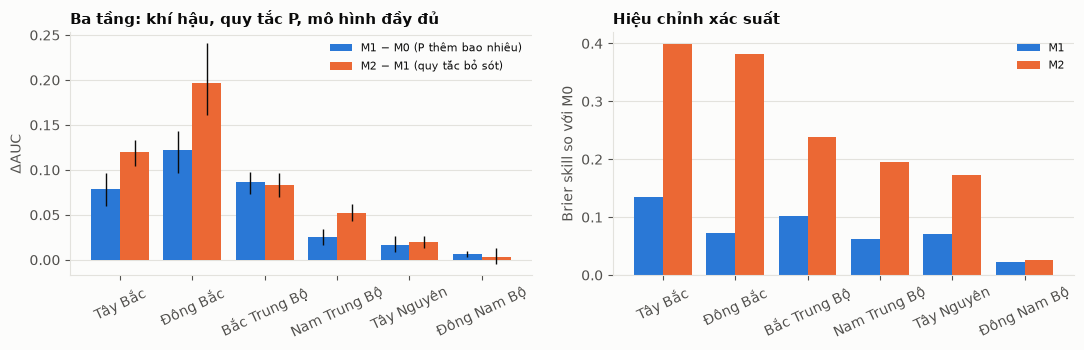

In [7]:
summary = pd.DataFrame({
    "AUC M0": metrics.groupby("region")["auc_m0"].mean(),
    "AUC M1": metrics.groupby("region")["auc_m1"].mean(),
    "AUC M2": metrics.groupby("region")["auc_m2"].mean(),
    "PR-AUC M0": metrics.groupby("region")["pr_m0"].mean(),
    "PR-AUC M1": metrics.groupby("region")["pr_m1"].mean(),
    "PR-AUC M2": metrics.groupby("region")["pr_m2"].mean(),
    "BSS M1": M.brier_skill(metrics, "m1"),
    "BSS M2": M.brier_skill(metrics, "m2"),
}).reindex(FOREST)
summary.index = [VN[k] for k in summary.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(FOREST))
axes[0].bar(x - 0.2, h1["delta"], 0.4, color=BLUE, label="M1 − M0 (P thêm bao nhiêu)")
axes[0].bar(x + 0.2, h3["delta"], 0.4, color=ORANGE, label="M2 − M1 (quy tắc bỏ sót)")
axes[0].errorbar(x - 0.2, h1["delta"], yerr=[h1["delta"] - h1["ci_lo"], h1["ci_hi"] - h1["delta"]], fmt="none", ecolor=INK, lw=1)
axes[0].errorbar(x + 0.2, h3["delta"], yerr=[h3["delta"] - h3["ci_lo"], h3["ci_hi"] - h3["delta"]], fmt="none", ecolor=INK, lw=1)
axes[0].set_xticks(x)
axes[0].set_xticklabels([VN[k] for k in FOREST], rotation=25)
axes[0].set_ylabel("ΔAUC")
axes[0].set_title("Ba tầng: khí hậu, quy tắc P, mô hình đầy đủ")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis="x", visible=False)

axes[1].bar(x, summary["BSS M1"], 0.4, color=BLUE, label="M1")
axes[1].bar(x + 0.4, summary["BSS M2"], 0.4, color=ORANGE, label="M2")
axes[1].set_xticks(x + 0.2)
axes[1].set_xticklabels(summary.index, rotation=25)
axes[1].set_ylabel("Brier skill so với M0")
axes[1].set_title("Hiệu chỉnh xác suất")
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
summary.round(3)

,Nesterov P,Rain history,Temp/humidity today,Weather anomaly/rolling,Terrain/land/location,Day of year
region,,,,,,
TB,0.005,0.034,0.087,0.077,0.034,0.041
DB,0.004,0.020,0.013,0.260,0.036,0.011
BTB,0.000,0.018,0.018,0.146,0.029,0.045
NTB,0.001,0.032,0.086,0.025,0.129,0.038
TN,0.001,0.056,0.039,0.006,0.008,0.139
DNB,0.001,0.032,0.031,-0.000,0.151,0.029


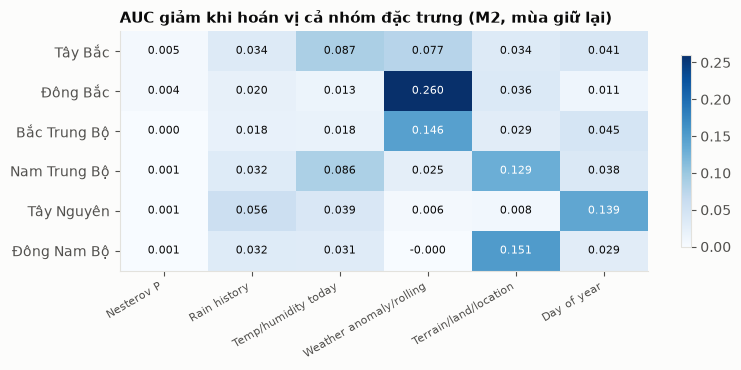

In [8]:
imp = importance.groupby("region")[list(M.FEATURE_GROUPS)].mean().reindex(FOREST)
imp.round(4).to_csv(RESULTS / "importance_groups.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(imp.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(imp.shape[1]))
ax.set_xticklabels(imp.columns, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(imp.shape[0]))
ax.set_yticklabels([VN[k] for k in imp.index])
ax.grid(False)
for i in range(imp.shape[0]):
    for j in range(imp.shape[1]):
        ax.text(j, i, f"{imp.values[i, j]:.3f}", ha="center", va="center", fontsize=8, color="white" if imp.values[i, j] > 0.1 else INK)
ax.set_title("AUC giảm khi hoán vị cả nhóm đặc trưng (M2, mùa giữ lại)")
plt.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
imp.round(3)

In [9]:
edges = [-1, 100, 300, 500, 1000, 2000, 4000, 1e9]
labels = ["<100", "100-300", "300-500", "500-1000", "1000-2000", "2000-4000", ">4000"]
model["Pbin"] = pd.cut(model["P_linear5_Ddew"], edges, labels=labels)
calibration = model.pivot_table(index="Pbin", columns="region", values="fire_any_forest", aggfunc="mean", observed=True)[FOREST]
calibration.round(4).to_csv(RESULTS / "calibration_by_pbin.csv")
spread = (calibration.max(axis=1) - calibration.min(axis=1)) * 100
print("Chênh lệch xác suất cháy giữa các vùng ở cùng mức P (điểm %):")
print(spread.round(0).to_dict())
(calibration * 100).round(1)

Chênh lệch xác suất cháy giữa các vùng ở cùng mức P (điểm %):
{'<100': 37.0, '100-300': 42.0, '300-500': 42.0, '500-1000': 34.0, '1000-2000': 33.0, '2000-4000': 33.0, '>4000': 52.0}


region,TB,DB,BTB,NTB,TN,DNB
Pbin,,,,,,
<100,20.7,9.2,21.7,26.4,45.7,20.4
100-300,18.6,10.7,30.4,31.9,52.8,26.5
300-500,32.9,18.3,45.4,44.8,60.2,32.1
500-1000,50.8,27.9,55.4,50.6,61.8,34.7
1000-2000,64.3,36.1,62.8,55.7,66.3,33.5
2000-4000,65.2,42.9,62.0,60.2,68.1,35.3
>4000,62.7,36.1,59.5,71.3,88.5,43.6


In [10]:
def transfer_scores(model, regions, outcome="fire_any_forest"):
    from sklearn.linear_model import LogisticRegression

    rows = []
    for target in regions:
        for season in sorted(model.loc[model["region"] == target, "season"].unique()):
            test = model[(model["region"] == target) & (model["season"] == season)]
            if test[outcome].nunique() < 2:
                continue
            own = model[(model["region"] == target) & (model["season"] != season)]
            other = model[(model["region"] != target) & model["region"].isin(regions)]
            row = {"region": target, "season": season}
            for name, train in [("own", own), ("other", other)]:
                fit = LogisticRegression(penalty=None, max_iter=1000).fit(np.log1p(train[[M.P_PRIMARY]]), train[outcome])
                row[f"brier_{name}"] = brier_score_loss(test[outcome], fit.predict_proba(np.log1p(test[[M.P_PRIMARY]]))[:, 1])
            row["brier_mean_rate"] = brier_score_loss(test[outcome], np.full(len(test), own[outcome].mean()))
            rows.append(row)
    return pd.DataFrame(rows)


transfer = transfer_scores(model, FOREST)
by_region = transfer.groupby("region")[["brier_mean_rate", "brier_own", "brier_other"]].mean().reindex(FOREST)
by_region["bss_own"] = 1 - by_region["brier_own"] / by_region["brier_mean_rate"]
by_region["bss_other"] = 1 - by_region["brier_other"] / by_region["brier_mean_rate"]
by_region.round(4).to_csv(RESULTS / "transfer_p_scale.csv")
by_region.round(4)

,brier_mean_rate,brier_own,brier_other,bss_own,bss_other
region,,,,,
TB,0.2503,0.2238,0.2278,0.1061,0.0898
DB,0.1835,0.1712,0.2212,0.0670,-0.2054
BTB,0.2460,0.2183,0.2225,0.1128,0.0958
NTB,0.2503,0.2237,0.2316,0.1064,0.0747
TN,0.2064,0.1843,0.2570,0.1071,-0.2453
DNB,0.2313,0.2224,0.2504,0.0387,-0.0824


Phép thử chuyển giao: dựng xác suất cháy chỉ từ log1p(P) bằng hồi quy logistic, một lần với dữ liệu của chính vùng đó (các mùa còn lại) và một lần với dữ liệu của 5 vùng còn lại, rồi chấm Brier trên mùa giữ lại. Cột bss_other so với bss_own cho biết thang P chuyển sang vùng khác thì mất bao nhiêu kỹ năng.

In [11]:
flags = ["is_weekend", "tet_win3", "giotuo_win1", "thanh_minh_win1", "holiday_solar"]
resid = oof[["season", "date", "y", "m1"]].join(model[flags])
resid["resid"] = resid["y"] - resid["m1"]


def season_sums(frame, mask):
    keep = frame[mask]
    ctrl = frame[~mask]
    seasons = np.sort(frame["season"].unique())
    return np.array([
        [keep.loc[keep["season"] == s, "resid"].sum(), (keep["season"] == s).sum(),
         ctrl.loc[ctrl["season"] == s, "resid"].sum(), (ctrl["season"] == s).sum()]
        for s in seasons
    ])


def resid_difference(sums):
    return sums[:, 0].sum() / sums[:, 1].sum() - sums[:, 2].sum() / sums[:, 3].sum()


rng = np.random.default_rng(0)
h4_rows = []
for flag in flags:
    mask = resid[flag] == 1
    sums = season_sums(resid, mask)
    point = resid_difference(sums)
    boot = np.array([resid_difference(sums[rng.integers(0, len(sums), len(sums))]) for _ in range(2000)])
    p = min(1.0, 2 * min((1 + np.sum(boot <= 0)) / 2001, (1 + np.sum(boot >= 0)) / 2001))
    h4_rows.append({
        "flag": flag, "n_flag_days": int(mask.sum()), "rate_flag": resid.loc[mask, "y"].mean(),
        "pred_flag": resid.loc[mask, "m1"].mean(), "mean_resid_diff": point,
        "ci_lo": np.percentile(boot, 2.5), "ci_hi": np.percentile(boot, 97.5), "p": p,
    })
h4 = pd.DataFrame(h4_rows)
h4["p_holm"] = M.holm(h4["p"])
h4.round(4).to_csv(RESULTS / "h4_calendar.csv", index=False)
h4.round(4)

,flag,n_flag_days,rate_flag,pred_flag,mean_resid_diff,ci_lo,ci_hi,p,p_holm
0,is_weekend,24109,0.4129,0.4200,-0.0095,-0.0225,0.0043,0.1599,0.4798
1,tet_win3,2618,0.3976,0.4508,-0.0546,-0.0917,-0.0132,0.0150,0.0600
2,giotuo_win1,1326,0.5520,0.4767,0.0768,0.0364,0.1245,0.0010,0.0050
3,thanh_minh_win1,1338,0.5306,0.4959,0.0356,-0.0154,0.0847,0.1659,0.4798
4,holiday_solar,1101,0.3896,0.4140,-0.0244,-0.0797,0.0287,0.3338,0.4798


In [12]:
def placebo_differences(frame, flag, shifts):
    real_dates = frame.loc[frame[flag] == 1, "date"].unique()
    out = {}
    for k in shifts:
        shifted = frame["date"].isin(pd.DatetimeIndex(real_dates) + pd.Timedelta(days=int(k)))
        out[k] = frame.loc[shifted, "resid"].mean() - frame.loc[~shifted, "resid"].mean()
    return pd.Series(out)


shifts = [k for k in range(-45, 46) if abs(k) > 7]
placebo_rows = []
for flag in flags[1:]:
    diffs = placebo_differences(resid, flag, shifts)
    real = h4.loc[h4["flag"] == flag, "mean_resid_diff"].iloc[0]
    placebo_rows.append({
        "flag": flag, "real": real, "placebo_sd": diffs.std(),
        "n_placebo_as_large": int((diffs.abs() >= abs(real)).sum()), "n_placebo": len(diffs),
        "p_placebo": (1 + (diffs.abs() >= abs(real)).sum()) / (1 + len(diffs)),
    })
placebo = pd.DataFrame(placebo_rows)
placebo.round(4).to_csv(RESULTS / "h4_placebo.csv", index=False)
placebo.round(4)

,flag,real,placebo_sd,n_placebo_as_large,n_placebo,p_placebo
0,tet_win3,-0.0546,0.0233,2,76,0.0390
1,giotuo_win1,0.0768,0.0400,7,76,0.1039
2,thanh_minh_win1,0.0356,0.0464,40,76,0.5325
3,holiday_solar,-0.0244,0.0366,43,76,0.5714


In [13]:
by_year = []
for flag in ["giotuo_win1", "thanh_minh_win1", "tet_win3"]:
    for season, g in resid.groupby("season"):
        mask = g[flag] == 1
        if mask.sum() >= 20:
            by_year.append({"flag": flag, "season": season, "diff": g.loc[mask, "resid"].mean() - g.loc[~mask, "resid"].mean()})
by_year = pd.DataFrame(by_year).pivot(index="season", columns="flag", values="diff")
print("Số mùa có hiệu ứng dương / âm:")
print(pd.DataFrame({"duong": (by_year > 0).sum(), "am": (by_year < 0).sum()}))
by_year.round(3)

Số mùa có hiệu ứng dương / âm:
                 duong  am
flag                      
giotuo_win1         11   1
tet_win3             3   9
thanh_minh_win1      8   4


flag,giotuo_win1,tet_win3,thanh_minh_win1
season,,,
2012,0.084,-0.102,0.183
2013,-0.029,-0.050,-0.033
2014,0.098,-0.041,0.076
2015,0.253,0.091,0.058
2016,0.004,0.001,-0.092
2017,0.050,-0.081,-0.046
2018,0.055,0.029,0.083
2019,0.029,-0.044,0.057
2020,0.073,-0.153,-0.114


In [14]:
base = clean[(clean["in_season"] == 1) & (clean["partial_season"] == 0)].copy()
base["season"] = base["season"].astype(int)
base["y_any"] = (base["n_hot_all"] > 0).astype(int)


def eligible_any(group):
    days = group[group["y_any"] == 1]
    return len(days) >= 150 and (days.groupby("season").size() >= 5).sum() >= 6


ok = base.groupby("prov").apply(eligible_any)
base = base[base["prov"].isin(ok[ok].index)].reset_index(drop=True)

h5_parts = []
for region in FOREST + ["DBSCL", "DBSH"]:
    part = base[base["region"] == region]
    o, _ = M.cross_validate(part, "y_any", fit_gbm=False)
    h5_parts.append(M.season_metrics(o, ["m0", "m1"]))
h5_metrics = pd.concat(h5_parts)
h5 = M.delta_table(h5_metrics, "m1", "m0", FOREST + ["DBSCL", "DBSH"])
h5["n_prov"] = [base.loc[base["region"] == r, "prov"].nunique() for r in h5["region"]]
h5.round(4).to_csv(RESULTS / "h5_any_hotspot.csv", index=False)
h5.round(4)

,region,seasons,auc_m0,auc_m1,delta,ci_lo,ci_hi,p,p_holm,n_prov
0,TB,11,0.7043,0.7899,0.0856,0.0694,0.1029,0.0005,0.004,4
1,DB,11,0.5824,0.6879,0.1055,0.0805,0.1264,0.0005,0.004,11
2,BTB,12,0.6193,0.7142,0.0948,0.0822,0.1074,0.0005,0.004,6
3,NTB,11,0.7783,0.8042,0.0258,0.0190,0.0328,0.0005,0.004,8
4,TN,11,0.8348,0.8561,0.0212,0.0080,0.0371,0.0010,0.004,5
5,DNB,11,0.7071,0.7253,0.0182,0.0122,0.0244,0.0005,0.004,6
6,DBSCL,11,0.8353,0.8417,0.0064,0.0017,0.0114,0.0025,0.004,12
7,DBSH,11,0.6549,0.6958,0.0410,0.0258,0.0553,0.0005,0.004,7


In [15]:
oni_rows = []
fire_days = model.groupby(["region", "prov", "season"])["fire_any_forest"].sum().rename("forest_days").reset_index()
fire_days["z"] = fire_days.groupby("prov")["forest_days"].transform(
    lambda s: (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else 0.0
)

for region in FOREST:
    z = fire_days[fire_days["region"] == region].groupby("season")["z"].mean()
    oni = model[model["region"] == region].groupby("season")["oni_lag3"].mean()
    joined = pd.concat([z, oni], axis=1, keys=["z", "oni"]).dropna()
    rho, p = spearmanr(joined["oni"], joined["z"])
    oni_rows.append({"region": region, "n_seasons": len(joined), "rho": rho, "p": p})
h6 = pd.DataFrame(oni_rows)
h6["p_holm"] = M.holm(h6["p"])

pooled = fire_days.groupby(["region", "season"])["z"].mean().reset_index()
pooled["oni"] = [model[(model["region"] == r) & (model["season"] == s)]["oni_lag3"].mean() for r, s in zip(pooled["region"], pooled["season"])]
rho_all, p_all = spearmanr(pooled["oni"], pooled["z"])
h6.round(4).to_csv(RESULTS / "h6_enso.csv", index=False)
print("Gộp 6 vùng: rho = %.2f, p = %.3f (n = %d vùng-mùa)" % (rho_all, p_all, len(pooled)))
h6.round(4)

Gộp 6 vùng: rho = 0.39, p = 0.001 (n = 67 vùng-mùa)


,region,n_seasons,rho,p,p_holm
0,TB,11,0.3000,0.3701,0.4931
1,DB,11,-0.3818,0.2466,0.4931
2,BTB,12,0.6154,0.0332,0.1658
3,NTB,11,0.5091,0.1097,0.3292
4,TN,11,0.6364,0.0353,0.1658
5,DNB,11,0.6636,0.0260,0.1559


In [16]:
oof_event = []
for region in FOREST:
    o, _ = M.cross_validate(model[model["region"] == region], "large_event_active", fit_gbm=True)
    oof_event.append(M.season_metrics(o, ["m0", "m1", "m2"]))
event_metrics = pd.concat(oof_event)
event_h1 = M.delta_table(event_metrics, "m1", "m0", FOREST)
event_h3 = M.delta_table(event_metrics, "m2", "m1", FOREST)
event = event_h1[["region", "auc_m0", "auc_m1", "delta", "p_holm"]].rename(columns={"delta": "d_m1_m0", "p_holm": "p_holm_m1"})
event["auc_m2"] = event_h3["auc_m2"].values
event["d_m2_m1"] = event_h3["delta"].values
event["p_holm_m2"] = event_h3["p_holm"].values
event["base_rate"] = [model.loc[model["region"] == r, "large_event_active"].mean() for r in event["region"]]
event.round(4).to_csv(RESULTS / "secondary_large_event.csv", index=False)
event.round(4)

,region,auc_m0,auc_m1,d_m1_m0,p_holm_m1,auc_m2,d_m2_m1,p_holm_m2,base_rate
0,TB,0.8068,0.8485,0.0417,0.0030,0.9101,0.0616,0.0030,0.2555
1,DB,0.6175,0.7361,0.1187,0.0030,0.8812,0.1451,0.0030,0.0837
2,BTB,0.7474,0.7983,0.0509,0.0030,0.8365,0.0381,0.0030,0.1907
3,NTB,0.8193,0.8348,0.0155,0.0030,0.8626,0.0278,0.0030,0.2446
4,TN,0.8557,0.8696,0.0138,0.0070,0.8741,0.0046,0.3918,0.5239
5,DNB,0.7296,0.7399,0.0103,0.0075,0.7294,-0.0105,0.8976,0.0683


Spearman (ΔAUC M1−M0 với tỉ lệ ngày cháy): -0.48
Spearman (ΔAUC M2−M1 với tỉ lệ rừng): 0.61


,prov,region,rate,auc_m0,auc_m1,auc_m2,d_p
6,binh thuan,NTB,0.559,0.824,0.860,0.879,0.037
13,gia lai,TN,0.750,0.817,0.856,0.891,0.039
0,ba ria vung tau,DNB,0.247,0.596,0.636,0.623,0.040
22,lang son,DB,0.256,0.525,0.743,0.910,0.218
2,bac kan,DB,0.190,0.504,0.725,0.904,0.221
17,hoa binh,TB,0.261,0.446,0.673,0.845,0.227


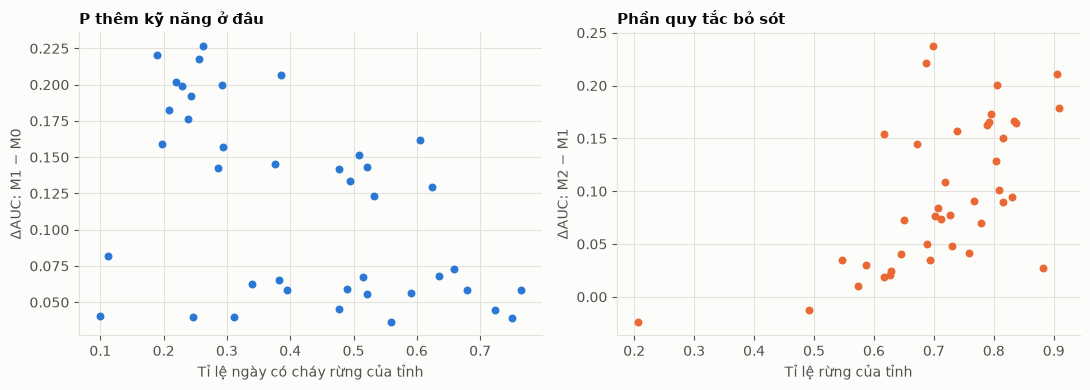

In [17]:
rows = []
for prov, g in oof.groupby("prov"):
    if g["y"].nunique() < 2:
        continue
    rows.append({
        "prov": prov, "region": g["region"].iloc[0], "n": len(g), "rate": g["y"].mean(),
        "auc_m0": roc_auc_score(g["y"], g["m0"]), "auc_m1": roc_auc_score(g["y"], g["m1"]), "auc_m2": roc_auc_score(g["y"], g["m2"]),
    })
by_prov = pd.DataFrame(rows).merge(clean.groupby("prov")[["forest_share", "area_km2"]].first().reset_index(), on="prov")
by_prov["d_p"] = by_prov["auc_m1"] - by_prov["auc_m0"]
by_prov["d_rest"] = by_prov["auc_m2"] - by_prov["auc_m1"]
by_prov.round(4).to_csv(RESULTS / "by_province.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(by_prov["rate"], by_prov["d_p"], color=BLUE, s=22)
axes[0].set_xlabel("Tỉ lệ ngày có cháy rừng của tỉnh")
axes[0].set_ylabel("ΔAUC: M1 − M0")
axes[0].set_title("P thêm kỹ năng ở đâu")
axes[1].scatter(by_prov["forest_share"], by_prov["d_rest"], color=ORANGE, s=22)
axes[1].set_xlabel("Tỉ lệ rừng của tỉnh")
axes[1].set_ylabel("ΔAUC: M2 − M1")
axes[1].set_title("Phần quy tắc bỏ sót")
fig.tight_layout()
print("Spearman (ΔAUC M1−M0 với tỉ lệ ngày cháy): %.2f" % spearmanr(by_prov["rate"], by_prov["d_p"])[0])
print("Spearman (ΔAUC M2−M1 với tỉ lệ rừng): %.2f" % spearmanr(by_prov["forest_share"], by_prov["d_rest"])[0])
by_prov.sort_values("d_p")[["prov", "region", "rate", "auc_m0", "auc_m1", "auc_m2", "d_p"]].round(3).iloc[[0, 1, 2, -3, -2, -1]]

Nhận xét (chỉ trên dữ liệu dev, chưa mở tập sealed):
1. H1 đúng ở cả 6 vùng (Holm 0,003): P thêm kỹ năng so với khí hậu, nhưng rất lệch, từ +0,122 AUC ở Đông Bắc xuống +0,006 ở Đông Nam Bộ. Kết quả khớp bảng xlsx cũ ở mọi vùng.
2. H3: mô hình đầy đủ hơn M1 rất nhiều ở Đông Bắc (+0,196), Tây Bắc (+0,120), Bắc Trung Bộ (+0,083), Nam Trung Bộ (+0,052). Ở Đông Nam Bộ M2 gần như bằng M1 (+0,004, Holm 0,225; bảng cũ ghi +0,016), tức ở đó chỉ số P đã lấy gần hết phần có thể dự báo từ thời tiết.
3. H2: 26 biến thể chỉ khác nhau cỡ 0,01 AUC. Biến thể tốt nhất hơn mặc định tối đa 0,006, có ý nghĩa sau Holm ở Bắc Trung Bộ, Tây Nguyên và Đông Nam Bộ nhưng nhỏ, và việc chọn trên cùng dữ liệu dev làm con số lạc quan.
4. Thang P không chuyển giao: dùng đường cong P của 5 vùng khác thì Brier skill tụt từ +0,07 xuống −0,21 ở Đông Bắc, từ +0,11 xuống −0,25 ở Tây Nguyên, từ +0,04 xuống −0,08 ở Đông Nam Bộ, tức tệ hơn dùng tỉ lệ cháy trung bình. Tây Bắc, Bắc Trung Bộ, Nam Trung Bộ chỉ mất ít. Cùng mức P, xác suất cháy khác nhau tới hàng chục điểm phần trăm giữa các vùng.
5. M2 dựa vào đâu khác nhau theo vùng: Đông Bắc và Bắc Trung Bộ chủ yếu là độ lệch so với khí hậu và thời tiết trượt, Tây Bắc là nhiệt độ ẩm độ hiện tại, Tây Nguyên là thời điểm trong năm, Nam Trung Bộ và Đông Nam Bộ là đặc trưng vị trí và lớp phủ (thực chất là phân biệt tỉnh nọ với tỉnh kia). P đứng riêng gần như không có đóng góp khi đã có các nhóm khác.
6. Rò rỉ mốc khí hậu của T13_anom, D13_anom không đáng kể (xem bảng so M2 với M2 tính lại mốc trong từng mùa huấn luyện).
7. Lịch (H4): Giỗ Tổ +7,7 điểm phần trăm, Holm 0,005, nhưng thử ngày giả cho 7/76 lần lệch ngày lớn tương đương (p placebo 0,10), nên chỉ nên coi là gợi ý. Tết giảm 5,5 điểm, Holm 0,06, và placebo cho p 0,04 nên cũng chưa vững. Cuối tuần, Thanh minh, lễ dương lịch không có ý nghĩa.
8. ENSO (H6): không vùng nào có ý nghĩa sau Holm (rho 0,3 đến 0,66 ở 4/6 vùng). Con số gộp 67 vùng-mùa (rho 0,39) không dùng được để suy luận vì các vùng cùng chia sẻ một chuỗi ONI theo mùa nên các điểm không độc lập; chỉ nên xem như hướng gợi ý với chỉ 11 đến 12 mùa mỗi vùng.
9. Biến cố "có bất kỳ điểm nóng": P chỉ thêm 0,006 AUC ở ĐBSCL (đốt đồng), 0,018 ở Đông Nam Bộ, so với 0,09 đến 0,11 ở Tây Bắc, Đông Bắc, Bắc Trung Bộ.
10. Sự kiện lớn (mục tiêu phụ) cùng kiểu: P thêm 0,119 AUC ở Đông Bắc nhưng M2 không hơn M1 ở Tây Nguyên và Đông Nam Bộ.
11. Theo tỉnh: P thêm kỹ năng nhiều ở tỉnh ít cháy (Spearman −0,48 giữa ΔAUC M1−M0 và tỉ lệ ngày cháy), phần quy tắc bỏ sót lớn hơn ở tỉnh nhiều rừng (Spearman +0,61 giữa ΔAUC M2−M1 và tỉ lệ rừng). Hòa Bình, Bắc Kạn, Lạng Sơn có ΔAUC M1−M0 khoảng 0,22 trong khi Bình Thuận, Gia Lai chỉ 0,04.